# Porównanie modeli prognostycznych

## Financial Decision Support System — prognoza stopy zwrotu w następnej sesji

Notebook porównuje trzy zaimplementowane i przetestowane podejścia:

- **Naive Zero Return** — prognoza zerowej stopy zwrotu;
- **ARIMA Walk-Forward** — oddzielny model i rząd ARIMA dla każdego instrumentu;
- **Random Forest** — kompaktowy model wykorzystujący cechy rynkowe.

Celem analizy nie jest wykazanie przewagi bardziej złożonego modelu za wszelką
cenę, lecz rzetelna ocena, czy modele uczą się sygnału przewyższającego prosty
benchmark na zbiorze walidacyjnym.

## Protokół ewaluacji i zamknięty test

Notebook analizuje wyłącznie zapisane wyniki ze zbioru **walidacyjnego**. Nie
otwiera zbioru testowego i nie uruchamia ponownego strojenia modeli.

Rzędy ARIMA zostały wybrane na treningu według AIC. Random Forest został
wytrenowany na treningu, a wszystkie trzy modele oceniono na dokładnie tych
samych obserwacjach walidacyjnych. Zbiór testowy pozostaje zamknięty do finalnej,
jednorazowej ewaluacji projektu.

Artefakty można odtworzyć poleceniami:

```bash
python3 -m backend.src.forecast.cli
python3 -m backend.src.forecast.arima_cli
python3 -m backend.src.forecast.random_forest_cli
```

In [1]:
from __future__ import annotations

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:,.8f}")

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titleweight"] = "bold"

## Lokalizacja i kontrakt artefaktów

Notebook korzysta wyłącznie z wyników wygenerowanych przez istniejące CLI.
Nie zapisuje nowych benchmarków ani nie modyfikuje danych projektu.

In [2]:
def find_project_root(start_directory: Path) -> Path:
    candidates = (start_directory, *start_directory.parents)

    for candidate in candidates:
        forecast_directory = candidate / "benchmark_results" / "forecast"
        if (candidate / "backend").is_dir() and forecast_directory.is_dir():
            return candidate

    raise FileNotFoundError(
        "Nie znaleziono projektu zawierającego backend/ i benchmark_results/forecast/."
    )


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
FORECAST_RESULTS_DIRECTORY = PROJECT_ROOT / "benchmark_results" / "forecast"

MODEL_SPECS = {
    "naive": {
        "label": "Naive Zero Return",
        "directory": "naive",
        "color": "#7F7F7F",
    },
    "arima": {
        "label": "ARIMA Walk-Forward",
        "directory": "arima",
        "color": "#DD8452",
    },
    "random_forest": {
        "label": "Random Forest",
        "directory": "random_forest",
        "color": "#2A6FBB",
    },
}

print(f"Project root: {PROJECT_ROOT}")
print(f"Forecast results: {FORECAST_RESULTS_DIRECTORY}")

Project root: project-root
Forecast results: benchmark_results/forecast


In [3]:
metric_frames = {}
observation_frames = {}
result_payloads = {}

for model_key, model_spec in MODEL_SPECS.items():
    model_directory = FORECAST_RESULTS_DIRECTORY / model_spec["directory"]
    required_paths = (
        model_directory / "forecast_metrics.csv",
        model_directory / "forecast_observations.csv",
        model_directory / "forecast_result.json",
    )
    missing_paths = [path for path in required_paths if not path.is_file()]

    if missing_paths:
        missing_text = ", ".join(str(path) for path in missing_paths)
        raise FileNotFoundError(
            f"Brakuje artefaktów modelu {model_key}: {missing_text}"
        )

    metric_frames[model_key] = pd.read_csv(required_paths[0])
    observation_frames[model_key] = pd.read_csv(
        required_paths[1],
        parse_dates=["date", "target_date"],
    )
    result_payloads[model_key] = json.loads(
        required_paths[2].read_text(encoding="utf-8")
    )

print(f"Wczytane modele: {', '.join(MODEL_SPECS)}")

Wczytane modele: naive, arima, random_forest


## Integralność porównania

Każdy model musi zawierać te same klucze obserwacji i te same wartości
rzeczywiste. Dodatkowo sprawdzamy skończoność predykcji, chronologię targetów,
brak duplikatów oraz zgodność błędu bezwzględnego.

In [4]:
OBSERVATION_COLUMNS = (
    "ticker",
    "date",
    "target_date",
    "actual",
    "prediction",
    "absolute_error",
    "actual_direction",
    "predicted_direction",
    "direction_correct",
)
KEY_COLUMNS = ["ticker", "date", "target_date"]

reference_observations = (
    observation_frames["naive"].sort_values(KEY_COLUMNS).reset_index(drop=True)
)

integrity_rows = []

for model_key, observations in observation_frames.items():
    ordered = observations.sort_values(KEY_COLUMNS).reset_index(drop=True)
    model_values = ordered[["actual", "prediction", "absolute_error"]].to_numpy(
        dtype=float
    )
    expected_absolute_error = np.abs(model_values[:, 0] - model_values[:, 1])

    keys_match = ordered[KEY_COLUMNS].equals(reference_observations[KEY_COLUMNS])
    actual_values_match = np.allclose(
        model_values[:, 0],
        reference_observations["actual"].to_numpy(dtype=float),
        rtol=0.0,
        atol=1e-15,
    )
    errors_match = np.allclose(
        model_values[:, 2],
        expected_absolute_error,
        rtol=1e-12,
        atol=1e-15,
    )

    integrity_rows.append(
        {
            "model": MODEL_SPECS[model_key]["label"],
            "observations": len(ordered),
            "columns_match": tuple(ordered.columns) == OBSERVATION_COLUMNS,
            "keys_match": keys_match,
            "actual_values_match": actual_values_match,
            "finite_numeric_values": bool(np.isfinite(model_values).all()),
            "absolute_errors_match": errors_match,
            "duplicate_keys": int(ordered.duplicated(KEY_COLUMNS).sum()),
            "non_future_targets": int(
                (ordered["target_date"] <= ordered["date"]).sum()
            ),
        }
    )

integrity_summary = pd.DataFrame(integrity_rows)
integrity_summary

,model,observations,columns_match,keys_match,actual_values_match,finite_numeric_values,absolute_errors_match,duplicate_keys,non_future_targets
0,Naive Zero Return,4786,True,True,True,True,True,0,0
1,ARIMA Walk-Forward,4786,True,True,True,True,True,0,0
2,Random Forest,4786,True,True,True,True,True,0,0


In [5]:
assert integrity_summary["columns_match"].all()
assert integrity_summary["keys_match"].all()
assert integrity_summary["actual_values_match"].all()
assert integrity_summary["finite_numeric_values"].all()
assert integrity_summary["absolute_errors_match"].all()
assert (integrity_summary["duplicate_keys"] == 0).all()
assert (integrity_summary["non_future_targets"] == 0).all()
assert {payload["evaluation_split"] for payload in result_payloads.values()} == {
    "validation"
}
assert {payload["target_definition"] for payload in result_payloads.values()} == {
    "next_session_simple_return"
}

print("Wspólne obserwacje walidacyjne:", len(reference_observations))
print(
    "Zakres dat cech:",
    reference_observations["date"].min().date(),
    "—",
    reference_observations["date"].max().date(),
)
print(
    "Zakres dat targetów:",
    reference_observations["target_date"].min().date(),
    "—",
    reference_observations["target_date"].max().date(),
)
print("Integralność porównania modeli: OK")

Wspólne obserwacje walidacyjne: 4786
Zakres dat cech: 2022-01-25 — 2024-04-27
Zakres dat targetów: 2022-01-26 — 2024-04-28
Integralność porównania modeli: OK


## Metryki ogólne

- **MAE** — przeciętny bezwzględny błąd prognozy;
- **RMSE** — silniej karze duże błędy;
- **R²** — poprawa względem prognozy stałą średnią; wartości bliskie zeru
  wskazują na bardzo słaby sygnał prognostyczny;
- **Directional accuracy** — udział poprawnie przewidzianych kierunków.

Dla dziennych stóp zwrotu niewielkie różnice są typowe, dlatego porównujemy
zarówno wartości bezwzględne, jak i zmianę względem prostego benchmarku.

In [6]:
overall_rows = []

for model_key, metrics in metric_frames.items():
    overall_values = metrics.loc[
        metrics["scope"] == "overall",
        [
            "observations",
            "mae",
            "mse",
            "rmse",
            "r2",
            "directional_accuracy",
        ],
    ].to_numpy(dtype=float)

    if overall_values.shape != (1, 6):
        raise ValueError(f"Model {model_key} nie ma dokładnie jednego wiersza overall.")

    values = overall_values[0]
    overall_rows.append(
        {
            "model_key": model_key,
            "model": MODEL_SPECS[model_key]["label"],
            "observations": int(values[0]),
            "mae": values[1],
            "mse": values[2],
            "rmse": values[3],
            "r2": values[4],
            "directional_accuracy": values[5],
        }
    )

overall_metrics = pd.DataFrame(overall_rows).set_index("model_key")
overall_metrics.sort_values("rmse")

,model,observations,mae,mse,rmse,r2,directional_accuracy
model_key,,,,,,,
random_forest,Random Forest,4786,0.01104250,0.00028565,0.01690127,0.00480414,0.50480568
naive,Naive Zero Return,4786,0.01101945,0.00028725,0.01694835,-0.00074850,0.00334308
arima,ARIMA Walk-Forward,4786,0.01115398,0.00028995,0.01702797,-0.01017288,0.50355203


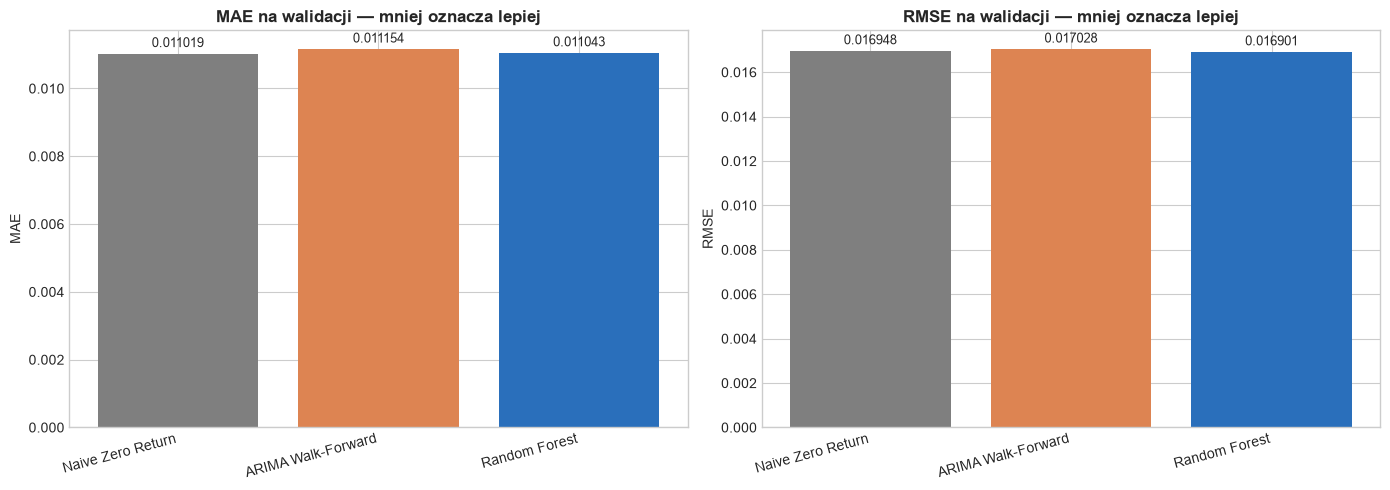

In [7]:
model_keys = list(MODEL_SPECS)
model_labels = [MODEL_SPECS[key]["label"] for key in model_keys]
model_colors = [MODEL_SPECS[key]["color"] for key in model_keys]
x_positions = np.arange(len(model_keys), dtype=float)

mae_values = overall_metrics.loc[model_keys, "mae"].to_numpy(dtype=float)
rmse_values = overall_metrics.loc[model_keys, "rmse"].to_numpy(dtype=float)

figure, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(x_positions, mae_values, color=model_colors)
axes[0].set_title("MAE na walidacji — mniej oznacza lepiej")
axes[0].set_xticks(x_positions)
axes[0].set_xticklabels(model_labels, rotation=15, ha="right")
axes[0].set_ylabel("MAE")

axes[1].bar(x_positions, rmse_values, color=model_colors)
axes[1].set_title("RMSE na walidacji — mniej oznacza lepiej")
axes[1].set_xticks(x_positions)
axes[1].set_xticklabels(model_labels, rotation=15, ha="right")
axes[1].set_ylabel("RMSE")

for axis in axes:
    for container in axis.containers:
        axis.bar_label(container, fmt="%.6f", padding=3, fontsize=9)

figure.tight_layout()
plt.show()

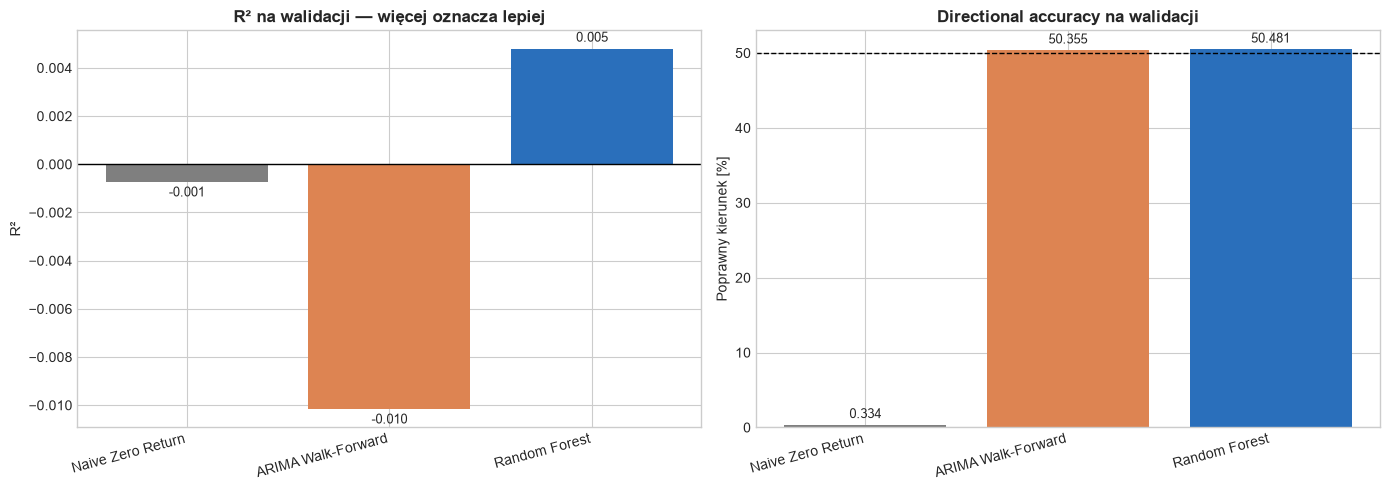

In [8]:
r2_values = overall_metrics.loc[model_keys, "r2"].to_numpy(dtype=float)
direction_values = overall_metrics.loc[
    model_keys,
    "directional_accuracy",
].to_numpy(dtype=float)

figure, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(x_positions, r2_values, color=model_colors)
axes[0].axhline(0.0, color="black", linewidth=1.0)
axes[0].set_title("R² na walidacji — więcej oznacza lepiej")
axes[0].set_xticks(x_positions)
axes[0].set_xticklabels(model_labels, rotation=15, ha="right")
axes[0].set_ylabel("R²")

axes[1].bar(x_positions, direction_values * 100.0, color=model_colors)
axes[1].axhline(50.0, color="black", linestyle="--", linewidth=1.0)
axes[1].set_title("Directional accuracy na walidacji")
axes[1].set_xticks(x_positions)
axes[1].set_xticklabels(model_labels, rotation=15, ha="right")
axes[1].set_ylabel("Poprawny kierunek [%]")

for axis in axes:
    for container in axis.containers:
        axis.bar_label(container, fmt="%.3f", padding=3, fontsize=9)

figure.tight_layout()
plt.show()

Prognoza zerowa jest bardzo silnym benchmarkiem dla stóp zwrotu, ale prawie
zawsze ma kierunek `flat`. Z tego powodu jej directional accuracy nie jest
bezpośrednio porównywalna z modelem wymuszającym dodatnią lub ujemną prognozę.
MAE, RMSE i R² pozostają podstawą oceny jakości wartości prognozy.

In [9]:
def overall_metric_value(model_key: str, metric_name: str) -> float:
    values = overall_metrics.loc[
        overall_metrics.index == model_key,
        metric_name,
    ].to_numpy(dtype=float)

    if values.shape != (1,):
        raise ValueError(
            f"Brak pojedynczej metryki {metric_name} dla modelu {model_key}."
        )

    return float(values[0])


naive_mae = overall_metric_value("naive", "mae")
naive_rmse = overall_metric_value("naive", "rmse")

relative_rows = []

for model_key in ("arima", "random_forest"):
    model_mae = overall_metric_value(model_key, "mae")
    model_rmse = overall_metric_value(model_key, "rmse")
    relative_rows.append(
        {
            "model": MODEL_SPECS[model_key]["label"],
            "mae_change_vs_naive_percent": (model_mae / naive_mae - 1.0) * 100.0,
            "rmse_change_vs_naive_percent": (model_rmse / naive_rmse - 1.0) * 100.0,
        }
    )

relative_comparison = pd.DataFrame(relative_rows).set_index("model")
relative_comparison

,mae_change_vs_naive_percent,rmse_change_vs_naive_percent
model,,
ARIMA Walk-Forward,1.22076842,0.46976327
Random Forest,0.20918140,-0.27781002


W tabeli powyżej wartość ujemna oznacza poprawę względem benchmarku. Pozwala to
odróżnić realną, choć niewielką przewagę od różnicy widocznej jedynie na dalszych
miejscach po przecinku.

## Wyniki według instrumentu

Wyniki ogólne mogą ukrywać różnice między klasami aktywów. Poniżej porównujemy
RMSE i directional accuracy osobno dla każdego tickera.

In [10]:
per_ticker_frames = []

for model_key, metrics in metric_frames.items():
    ticker_metrics = metrics.loc[metrics["scope"] == "ticker"].copy()
    ticker_metrics["model_key"] = model_key
    ticker_metrics["model"] = MODEL_SPECS[model_key]["label"]
    per_ticker_frames.append(ticker_metrics)

per_ticker_metrics = pd.concat(per_ticker_frames, ignore_index=True)
per_ticker_metrics[
    [
        "ticker",
        "model",
        "observations",
        "mae",
        "rmse",
        "r2",
        "directional_accuracy",
    ]
].sort_values(["ticker", "rmse"])

,ticker,model,observations,mae,rmse,r2,directional_accuracy
8,AGG,ARIMA Walk-Forward,566,0.00378691,0.00477763,0.00102607,0.55477032
0,AGG,Naive Zero Return,566,0.00382064,0.00478278,-0.00113044,0.00000000
16,AGG,Random Forest,566,0.00383622,0.00480460,-0.01028345,0.48233216
17,BTC-USD,Random Forest,824,0.01947257,0.02884476,0.00535945,0.48179612
1,BTC-USD,Naive Zero Return,824,0.01934186,0.02894212,-0.00136624,0.00000000
9,BTC-USD,ARIMA Walk-Forward,824,0.01951789,0.02895876,-0.00251841,0.49271845
18,EPOL,Random Forest,566,0.01596266,0.02079966,0.00879385,0.51060071
2,EPOL,Naive Zero Return,566,0.01597314,0.02090024,-0.00081565,0.01413428
10,EPOL,ARIMA Walk-Forward,566,0.01607603,0.02100268,-0.01064999,0.47879859
11,GLD,ARIMA Walk-Forward,566,0.00680194,0.00894109,-0.00075499,0.52120141


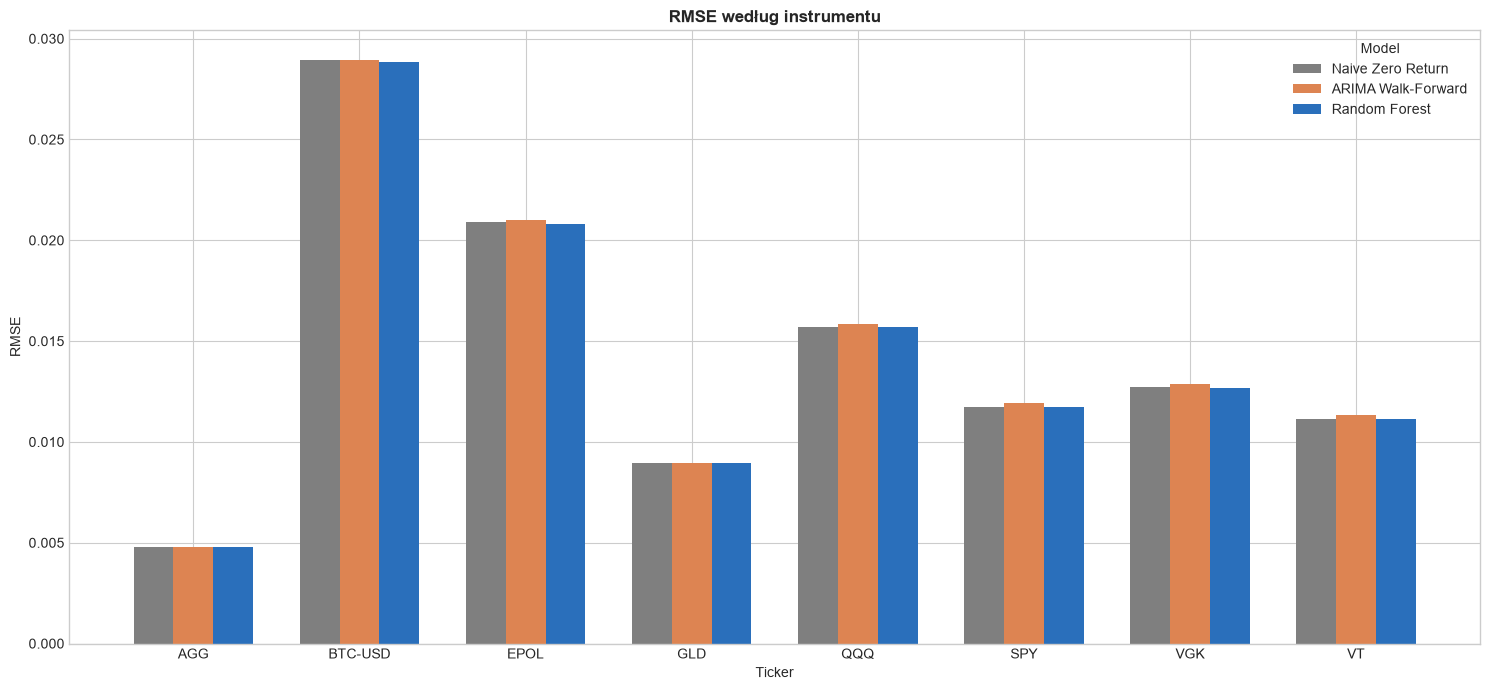

In [11]:
tickers = sorted(per_ticker_metrics["ticker"].astype(str).unique().tolist())
ticker_positions = np.arange(len(tickers), dtype=float)
bar_width = 0.24

figure, axis = plt.subplots(figsize=(15, 7))

for model_position, model_key in enumerate(model_keys):
    model_ticker_metrics = (
        per_ticker_metrics.loc[
            per_ticker_metrics["model_key"] == model_key,
            ["ticker", "rmse"],
        ]
        .set_index("ticker")
        .reindex(tickers)
    )
    rmse_by_ticker = model_ticker_metrics["rmse"].to_numpy(dtype=float)
    axis.bar(
        ticker_positions + (model_position - 1) * bar_width,
        rmse_by_ticker,
        width=bar_width,
        label=MODEL_SPECS[model_key]["label"],
        color=MODEL_SPECS[model_key]["color"],
    )

axis.set_title("RMSE według instrumentu")
axis.set_xticks(ticker_positions)
axis.set_xticklabels(tickers)
axis.set_xlabel("Ticker")
axis.set_ylabel("RMSE")
axis.legend(title="Model")
figure.tight_layout()
plt.show()

In [12]:
metric_winners = []

for ticker in tickers:
    ticker_results = per_ticker_metrics.loc[
        per_ticker_metrics["ticker"] == ticker
    ].copy()
    mae_position = int(np.argmin(ticker_results["mae"].to_numpy(dtype=float)))
    rmse_position = int(np.argmin(ticker_results["rmse"].to_numpy(dtype=float)))
    result_labels = ticker_results["model"].astype(str).tolist()

    metric_winners.append(
        {
            "ticker": ticker,
            "lowest_mae": result_labels[mae_position],
            "lowest_rmse": result_labels[rmse_position],
        }
    )

winner_summary = pd.DataFrame(metric_winners).set_index("ticker")
winner_summary

,lowest_mae,lowest_rmse
ticker,,
AGG,ARIMA Walk-Forward,ARIMA Walk-Forward
BTC-USD,Naive Zero Return,Random Forest
EPOL,Random Forest,Random Forest
GLD,ARIMA Walk-Forward,ARIMA Walk-Forward
QQQ,Naive Zero Return,Random Forest
SPY,Naive Zero Return,Random Forest
VGK,Random Forest,Random Forest
VT,Random Forest,Random Forest


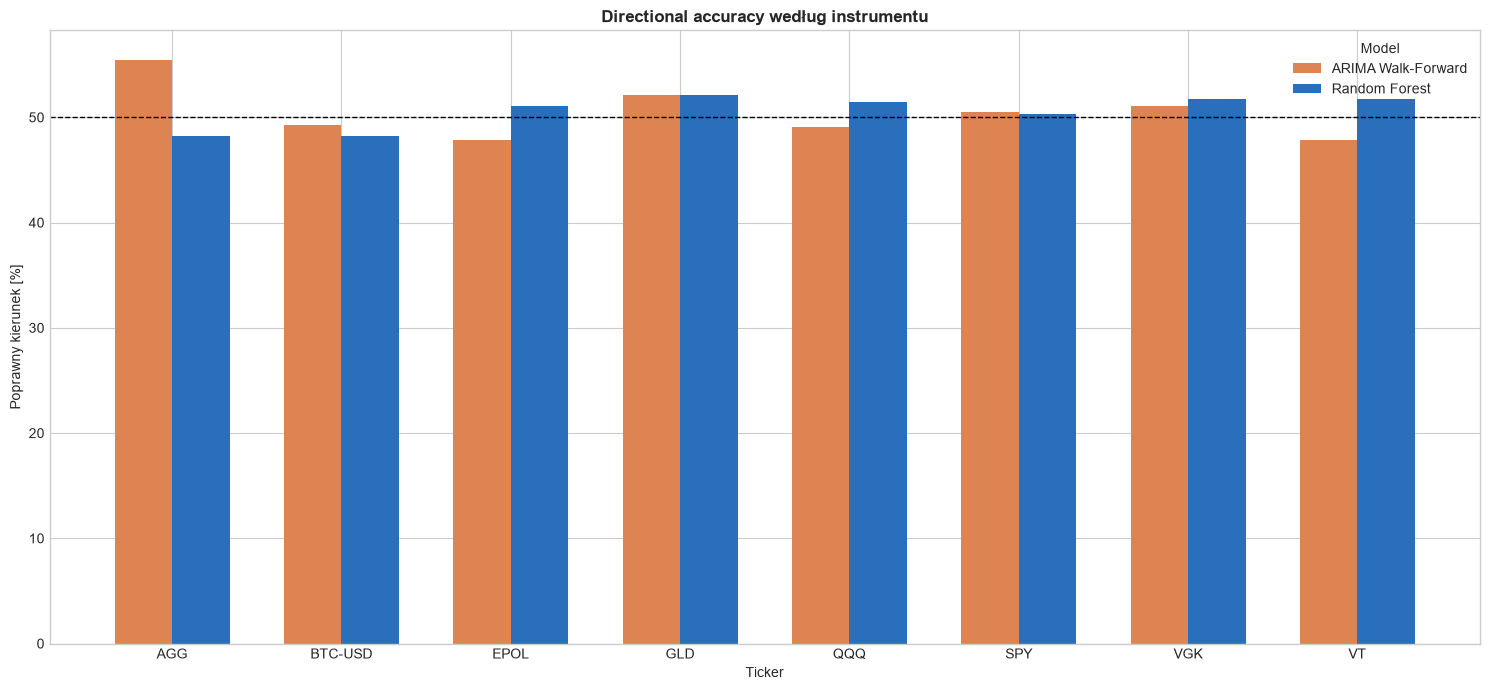

In [13]:
figure, axis = plt.subplots(figsize=(15, 7))

direction_model_keys = ["arima", "random_forest"]
direction_bar_width = 0.34

for model_position, model_key in enumerate(direction_model_keys):
    model_ticker_metrics = (
        per_ticker_metrics.loc[
            per_ticker_metrics["model_key"] == model_key,
            ["ticker", "directional_accuracy"],
        ]
        .set_index("ticker")
        .reindex(tickers)
    )
    direction_by_ticker = (
        model_ticker_metrics["directional_accuracy"].to_numpy(dtype=float) * 100.0
    )
    axis.bar(
        ticker_positions + (model_position - 0.5) * direction_bar_width,
        direction_by_ticker,
        width=direction_bar_width,
        label=MODEL_SPECS[model_key]["label"],
        color=MODEL_SPECS[model_key]["color"],
    )

axis.axhline(50.0, color="black", linestyle="--", linewidth=1.0)
axis.set_title("Directional accuracy według instrumentu")
axis.set_xticks(ticker_positions)
axis.set_xticklabels(tickers)
axis.set_xlabel("Ticker")
axis.set_ylabel("Poprawny kierunek [%]")
axis.legend(title="Model")
figure.tight_layout()
plt.show()

## Rozkład i struktura błędów

Średnie metryki nie pokazują, czy wynik jest stabilny, czy zdominowany przez
kilka ekstremalnych sesji. Porównujemy rozkłady błędu bezwzględnego oraz przebieg
prognoz dla SPY jako czytelnego przykładu rynku akcji USA.

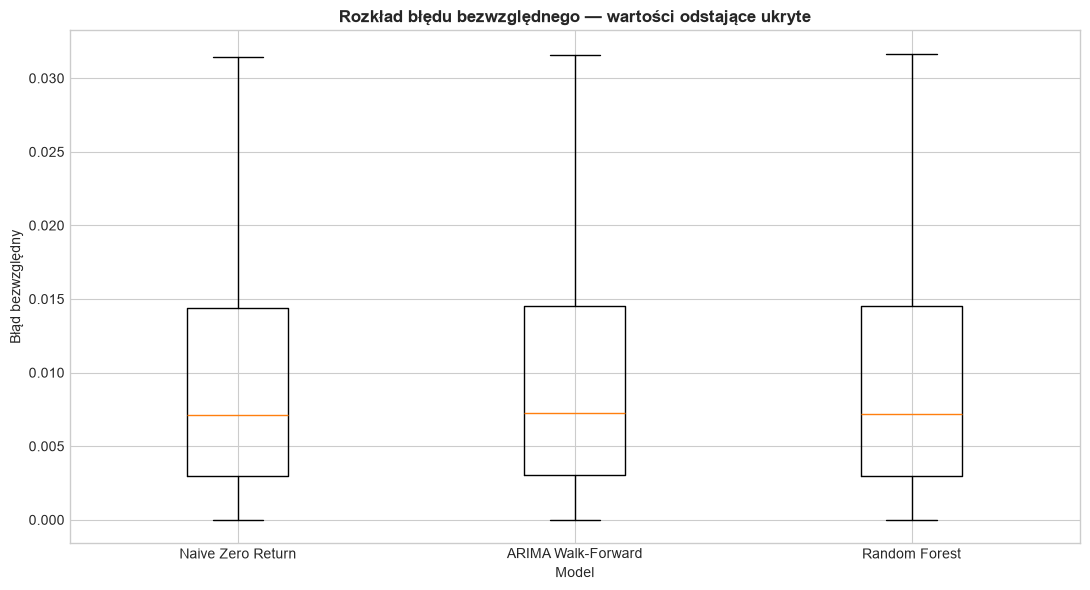

In [14]:
absolute_error_arrays = [
    observation_frames[model_key]["absolute_error"].to_numpy(dtype=float)
    for model_key in model_keys
]

figure, axis = plt.subplots(figsize=(11, 6))
axis.boxplot(
    absolute_error_arrays,
    tick_labels=model_labels,
    showfliers=False,
)
axis.set_title("Rozkład błędu bezwzględnego — wartości odstające ukryte")
axis.set_xlabel("Model")
axis.set_ylabel("Błąd bezwzględny")
figure.tight_layout()
plt.show()

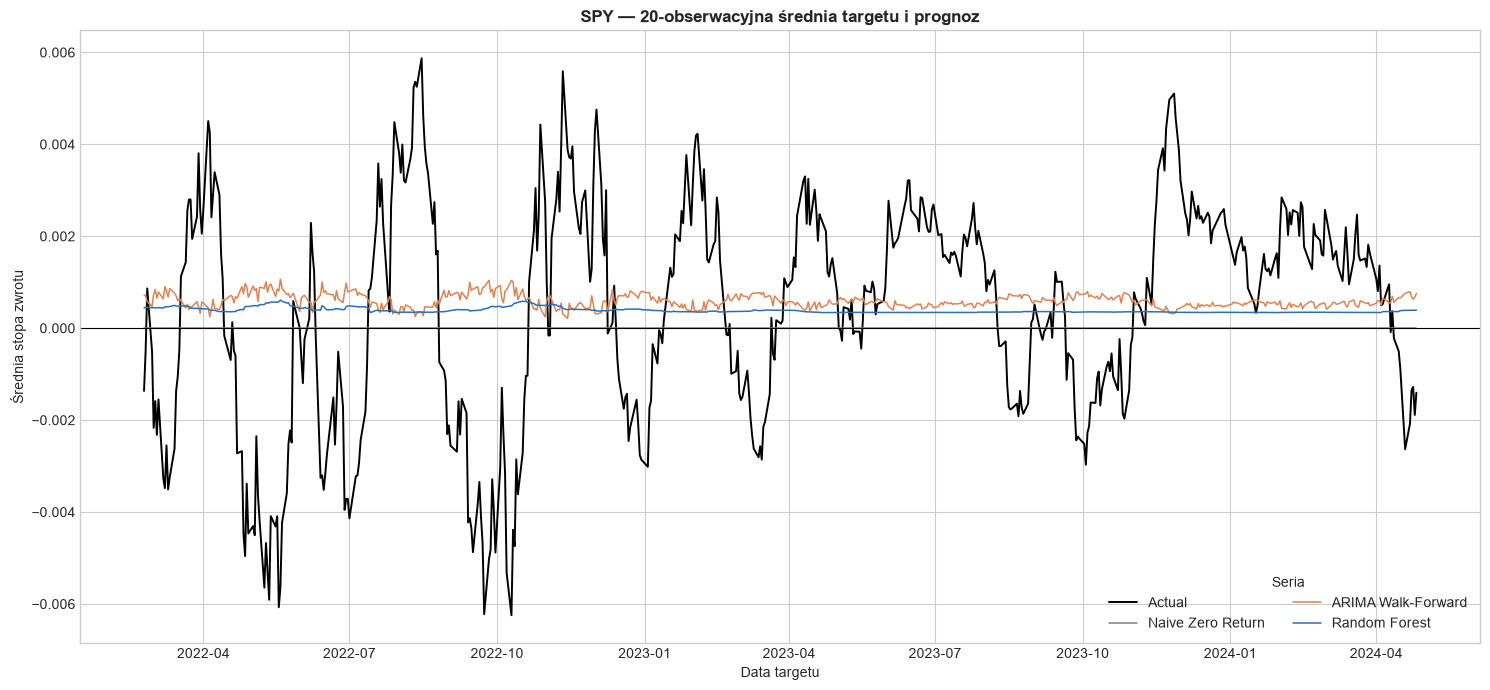

In [15]:
representative_ticker = "SPY"
representative = reference_observations.loc[
    reference_observations["ticker"] == representative_ticker,
    ["target_date", "actual"],
].sort_values("target_date")

rolling_comparison = representative.set_index("target_date").rename(
    columns={"actual": "Actual"}
)

for model_key in model_keys:
    model_observations = observation_frames[model_key]
    model_predictions = model_observations.loc[
        model_observations["ticker"] == representative_ticker,
        ["target_date", "prediction"],
    ].sort_values("target_date")
    prediction_series = model_predictions.set_index("target_date")["prediction"]
    rolling_comparison[MODEL_SPECS[model_key]["label"]] = prediction_series

rolling_comparison = rolling_comparison.rolling(
    window=20,
    min_periods=20,
).mean()

figure, axis = plt.subplots(figsize=(15, 7))
axis.plot(
    rolling_comparison.index,
    rolling_comparison["Actual"].to_numpy(dtype=float),
    label="Actual",
    color="black",
    linewidth=1.4,
)

for model_key in model_keys:
    model_label = MODEL_SPECS[model_key]["label"]
    axis.plot(
        rolling_comparison.index,
        rolling_comparison[model_label].to_numpy(dtype=float),
        label=model_label,
        color=MODEL_SPECS[model_key]["color"],
        linewidth=1.1,
    )

axis.axhline(0.0, color="black", linewidth=0.8)
axis.set_title("SPY — 20-obserwacyjna średnia targetu i prognoz")
axis.set_xlabel("Data targetu")
axis.set_ylabel("Średnia stopa zwrotu")
axis.legend(title="Seria", ncol=2)
figure.tight_layout()
plt.show()

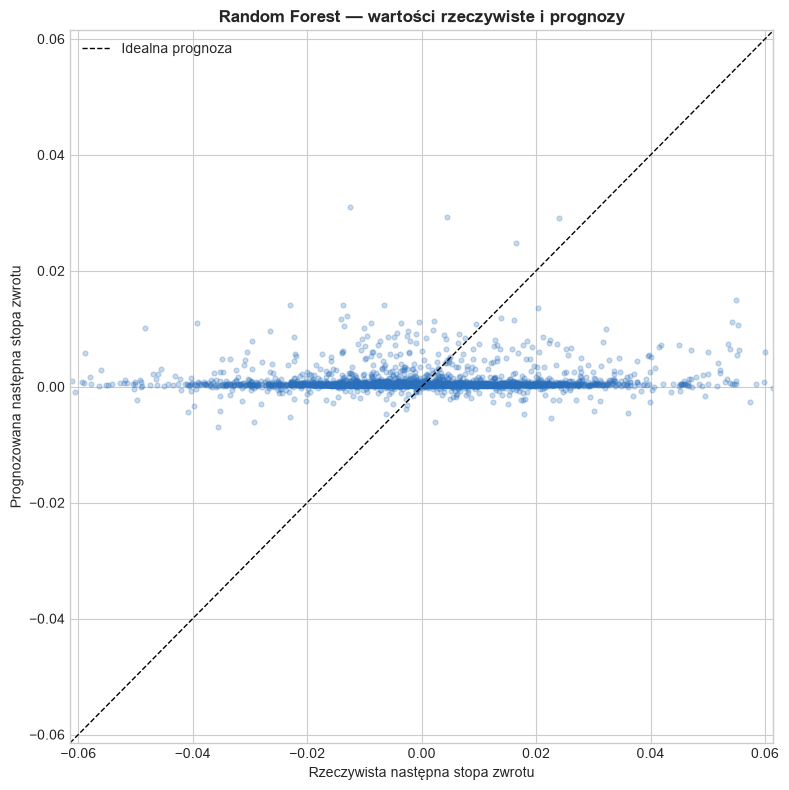

In [16]:
random_forest_observations = observation_frames["random_forest"]
actual_values = random_forest_observations["actual"].to_numpy(dtype=float)
prediction_values = random_forest_observations["prediction"].to_numpy(dtype=float)
plot_limit = float(
    np.quantile(
        np.abs(np.concatenate([actual_values, prediction_values])),
        0.995,
    )
)

figure, axis = plt.subplots(figsize=(8, 8))
axis.scatter(
    actual_values,
    prediction_values,
    s=12,
    alpha=0.25,
    color=MODEL_SPECS["random_forest"]["color"],
)
axis.plot(
    [-plot_limit, plot_limit],
    [-plot_limit, plot_limit],
    color="black",
    linestyle="--",
    linewidth=1.0,
    label="Idealna prognoza",
)
axis.set_xlim(-plot_limit, plot_limit)
axis.set_ylim(-plot_limit, plot_limit)
axis.set_title("Random Forest — wartości rzeczywiste i prognozy")
axis.set_xlabel("Rzeczywista następna stopa zwrotu")
axis.set_ylabel("Prognozowana następna stopa zwrotu")
axis.legend()
figure.tight_layout()
plt.show()

In [17]:
largest_random_forest_errors = (
    random_forest_observations.sort_values(
        "absolute_error",
        ascending=False,
    )
    .head(10)
    .loc[
        :,
        [
            "ticker",
            "date",
            "target_date",
            "actual",
            "prediction",
            "absolute_error",
            "direction_correct",
        ],
    ]
    .reset_index(drop=True)
)

largest_random_forest_errors

,ticker,date,target_date,actual,prediction,absolute_error,direction_correct
0,BTC-USD,2022-06-12,2022-06-13,-0.15974726,0.00175020,0.16149746,False
1,BTC-USD,2022-02-27,2022-02-28,0.14541184,-0.00028506,0.14569689,False
2,BTC-USD,2022-11-08,2022-11-09,-0.14349022,-0.00284451,0.14064571,True
3,BTC-USD,2022-02-03,2022-02-04,0.11697807,0.00031260,0.11666547,True
4,BTC-USD,2022-05-08,2022-05-09,-0.11046370,0.00135727,0.11182097,False
5,BTC-USD,2022-09-08,2022-09-09,0.10612188,0.00019752,0.10592436,True
6,BTC-USD,2023-10-22,2023-10-23,0.10309891,0.00173915,0.10135975,True
7,BTC-USD,2022-08-18,2022-08-19,-0.10059931,0.00026679,0.10086611,False
8,BTC-USD,2022-11-07,2022-11-08,-0.10006132,0.00052298,0.10058430,False
9,BTC-USD,2024-03-19,2024-03-20,0.09692505,-0.00184870,0.09877375,False


Największe błędy są ważnym wynikiem, a nie elementem do ukrycia. Pokazują, że
model oparty na typowych zależnościach historycznych nie przewiduje skutecznie
rzadkich szoków rynkowych. W aplikacji prognoza musi być więc prezentowana razem
z analizą ryzyka i scenariuszami, a nie jako pewna wartość przyszłego zwrotu.

## Dobór rzędów ARIMA

Każdy ticker otrzymał własny rząd ARIMA wybrany na danych treningowych według
AIC. Notebook pokazuje zarówno wybrane konfiguracje, jak i różnicę AIC względem
najlepszego kandydata dla danego instrumentu.

In [18]:
arima_directory = FORECAST_RESULTS_DIRECTORY / MODEL_SPECS["arima"]["directory"]
arima_selection_payload = json.loads(
    (arima_directory / "arima_order_selection.json").read_text(encoding="utf-8")
)
arima_scores = pd.read_csv(arima_directory / "arima_order_selection_scores.csv")

assert arima_selection_payload["selection_dataset"] == "training"
assert arima_selection_payload["criterion"] == "aic"
assert int(arima_scores["selected"].sum()) == len(tickers)
assert arima_scores.groupby("ticker")["selected"].sum().eq(1).all()

selected_order_rows = []

for ticker, order in sorted(arima_selection_payload["selected_orders"].items()):
    selected_order_rows.append(
        {
            "ticker": ticker,
            "selected_order": f"({order[0]}, {order[1]}, {order[2]})",
        }
    )

selected_arima_orders = pd.DataFrame(selected_order_rows).set_index("ticker")
selected_arima_orders

,selected_order
ticker,
AGG,"(2, 0, 0)"
BTC-USD,"(0, 0, 0)"
EPOL,"(2, 0, 0)"
GLD,"(0, 0, 0)"
QQQ,"(2, 0, 0)"
SPY,"(2, 0, 0)"
VGK,"(2, 0, 0)"
VT,"(2, 0, 0)"


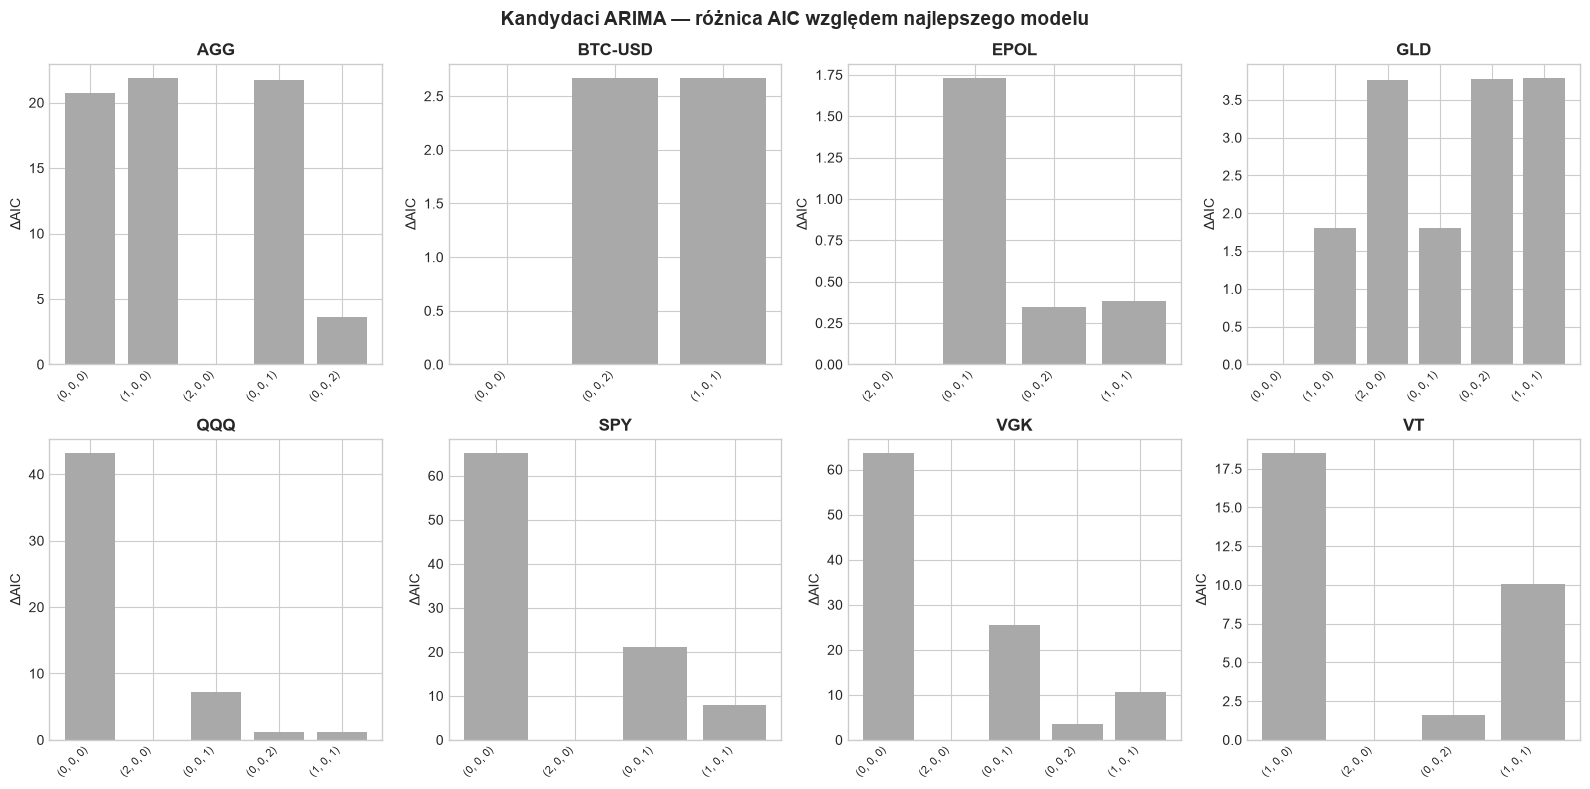

In [19]:
figure, axes = plt.subplots(2, 4, figsize=(16, 8))

for ticker, axis in zip(tickers, axes.ravel(), strict=True):
    ticker_scores = arima_scores.loc[arima_scores["ticker"] == ticker].copy()
    finite_scores = ticker_scores.loc[
        ticker_scores["converged"] & np.isfinite(ticker_scores["aic"])
    ].copy()
    minimum_aic = float(finite_scores["aic"].to_numpy(dtype=float).min())
    delta_aic = finite_scores["aic"].to_numpy(dtype=float) - minimum_aic
    order_labels = [
        f"({int(p)}, {int(d)}, {int(q)})"
        for p, d, q in finite_scores[["p", "d", "q"]].to_numpy(dtype=int)
    ]
    selected_flags = finite_scores["selected"].to_numpy(dtype=bool)
    candidate_colors = [
        "#C44E52" if is_selected else "#A9A9A9" for is_selected in selected_flags
    ]

    positions = np.arange(len(order_labels), dtype=float)
    axis.bar(positions, delta_aic, color=candidate_colors)
    axis.set_xticks(positions)
    axis.set_xticklabels(order_labels, rotation=45, ha="right", fontsize=8)
    axis.set_title(ticker)
    axis.set_ylabel("ΔAIC")

figure.suptitle(
    "Kandydaci ARIMA — różnica AIC względem najlepszego modelu",
    fontsize=14,
    fontweight="bold",
)
figure.tight_layout()
plt.show()

## Automatyczne podsumowanie porównania

Wnioski są wyliczane z bieżących artefaktów, dzięki czemu nie dezaktualizują się
po ponownym uruchomieniu benchmarków.

In [20]:
rmse_values = overall_metrics.loc[model_keys, "rmse"].to_numpy(dtype=float)
r2_values = overall_metrics.loc[model_keys, "r2"].to_numpy(dtype=float)
mae_values = overall_metrics.loc[model_keys, "mae"].to_numpy(dtype=float)

best_rmse_position = int(np.argmin(rmse_values))
best_r2_position = int(np.argmax(r2_values))
best_mae_position = int(np.argmin(mae_values))

best_rmse_key = model_keys[best_rmse_position]
best_r2_key = model_keys[best_r2_position]
best_mae_key = model_keys[best_mae_position]
random_forest_rmse_change = (
    overall_metric_value("random_forest", "rmse") / naive_rmse - 1.0
) * 100.0
random_forest_mae_change = (
    overall_metric_value("random_forest", "mae") / naive_mae - 1.0
) * 100.0

print("Najważniejsze wyniki walidacyjne:")
print(f"  Najniższe MAE: {MODEL_SPECS[best_mae_key]['label']}")
print(f"  Najniższe RMSE: {MODEL_SPECS[best_rmse_key]['label']}")
print(f"  Najwyższe R²: {MODEL_SPECS[best_r2_key]['label']}")
print(f"  Zmiana RMSE Random Forest względem Naive: {random_forest_rmse_change:.4f}%")
print(f"  Zmiana MAE Random Forest względem Naive: {random_forest_mae_change:.4f}%")
print(
    "  Interpretacja: Random Forest jest najlepszym modelem według RMSE i R², "
    "ale skala przewagi nad benchmarkiem jest niewielka."
)

Najważniejsze wyniki walidacyjne:
  Najniższe MAE: Naive Zero Return
  Najniższe RMSE: Random Forest
  Najwyższe R²: Random Forest
  Zmiana RMSE Random Forest względem Naive: -0.2778%
  Zmiana MAE Random Forest względem Naive: 0.2092%
  Interpretacja: Random Forest jest najlepszym modelem według RMSE i R², ale skala przewagi nad benchmarkiem jest niewielka.


## Wnioski i decyzja projektowa

- **Naive Zero Return** pozostaje niezbędnym i bardzo konkurencyjnym benchmarkiem.
- **ARIMA Walk-Forward** osiąga directional accuracy bliskie 50%, ale nie poprawia
  ogólnych MAE, RMSE ani R² względem prognozy zerowej.
- **Random Forest** uzyskuje najlepsze ogólne RMSE i R², lecz poprawa względem
  benchmarku jest mała i nie obejmuje każdego instrumentu ani każdej metryki.
- Niskie wartości R² potwierdzają, że jednodniowe stopy zwrotu zawierają bardzo
  słaby przewidywalny sygnał.
- Ekstremalne sesje pozostają trudne do prognozowania. Wynik modelu powinien być
  łączony z ryzykiem, scenariuszami i wyjaśnieniami XAI.

Random Forest zostaje przyjęty jako **główny model ML i obiekt analiz XAI**, a
Naive jako obowiązkowy punkt odniesienia. Nie tworzymy hybrydy dobieranej po
wynikach walidacyjnych dla poszczególnych tickerów, ponieważ zwiększałoby to
ryzyko selekcyjnego dopasowania.

Zbiór testowy pozostaje niewykorzystany. Zostanie otwarty dopiero podczas
finalnej, jednorazowej oceny całego rozwiązania.